# Predicting Term Deposit Subscription – Bank Marketing (UCI)

**Module:** 6COSC017C-n Machine Learning and Data Analytics – Coursework 1

**Business question:** Before a bank calls a client, can we predict if the client will open a term deposit?
If we can, the bank can call the most promising clients first. This saves time and money.

**Dataset:** Bank Marketing (with social/economic context), Moro, Cortez and Rita (2014).
Source: https://archive.ics.uci.edu/dataset/222/bank+marketing (licence: CC BY 4.0).

**Notebook plan**
1. Load the data
2. Exploratory Data Analysis (EDA)
3. Data preparation (cleaning, errors, missing values, feature engineering, scaling, split)
4. Model training with hyperparameter tuning (4 models)
5. Model evaluation on the test set
6. Saving the models for the Streamlit app

In [1]:
# Libraries
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

# Our own shared code (also used by the Streamlit app)
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.bank_ml import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, RANDOM_STATE,
                         build_preprocessor, clean, add_features, load_raw, split_xy)

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
np.random.seed(RANDOM_STATE)

def save(name):
    # Save every figure, so we can use it in the report
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Load the data

The data comes from one source: the file `bank-additional-full.csv` from the UCI Machine Learning Repository.
The file uses `;` as a separator. Every row is one phone call to one client.

In [2]:
raw = load_raw(ROOT / "data" / "bank-additional-full.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Data types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

## 2. Exploratory Data Analysis

### 2.1 Summary statistics
We look at the mean, standard deviation, variance, median and other measures.
They help us to see the centre and the spread of each numeric column, and to find strange values.

In [4]:
num_cols = raw.select_dtypes("number").columns
summary = raw[num_cols].describe().T
summary["variance"] = raw[num_cols].var()
summary["median"] = raw[num_cols].median()
summary["skew"] = raw[num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,variance,median,skew
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00,108.60,38.00,0.78
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00,67225.73,180.00,3.26
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00,7.67,2.00,4.76
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00,34935.69,999.00,-4.92
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00,0.24,0.00,3.83
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40,2.47,1.10,-0.72
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77,0.34,93.75,-0.23
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90,21.42,-41.80,0.30
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04,3.01,4.86,-0.71
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10,5220.28,5191.00,-1.04


In [5]:
# Categorical columns: number of categories and the most common value
raw.describe(exclude="number").T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [6]:
# Missing values: there are no NaN values, but 'unknown' is used as a missing value
print("NaN values:", raw.isna().sum().sum())
unknown = (raw == "unknown").sum()
unknown = unknown[unknown > 0].to_frame("unknown_count")
unknown["percent"] = (unknown["unknown_count"] / len(raw) * 100).round(2)
unknown

NaN values: 0


,unknown_count,percent
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


In [7]:
print("Duplicated rows:", raw.duplicated().sum())
print("pdays = 999 (code for 'never contacted'):", round((raw['pdays'] == 999).mean() * 100, 2), "%")

Duplicated rows: 12
pdays = 999 (code for 'never contacted'): 96.32 %


### 2.2 Target variable
The target `y` shows if the client opened a term deposit. We must know the class balance,
because it changes which metrics we can trust.

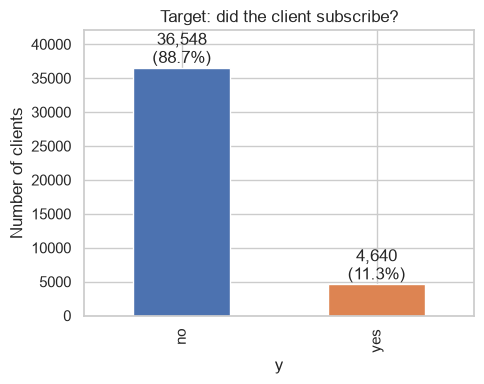

In [8]:
ax = raw["y"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(5, 4))
for p in ax.patches:
    ax.annotate(f"{p.get_height():,}\n({p.get_height() / len(raw):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Target: did the client subscribe?")
ax.set_xlabel("y"); ax.set_ylabel("Number of clients")
ax.set_ylim(0, raw["y"].value_counts().max() * 1.15)
save("target_distribution")

Only about 11% of clients said "yes". The data is **imbalanced**. A model that always says "no" gets about 89% accuracy,
but it is useless for the bank. So accuracy alone is not a good metric here.

### 2.3 Distributions of numeric columns
Histograms show the shape of each column (normal, skewed, many repeated values).

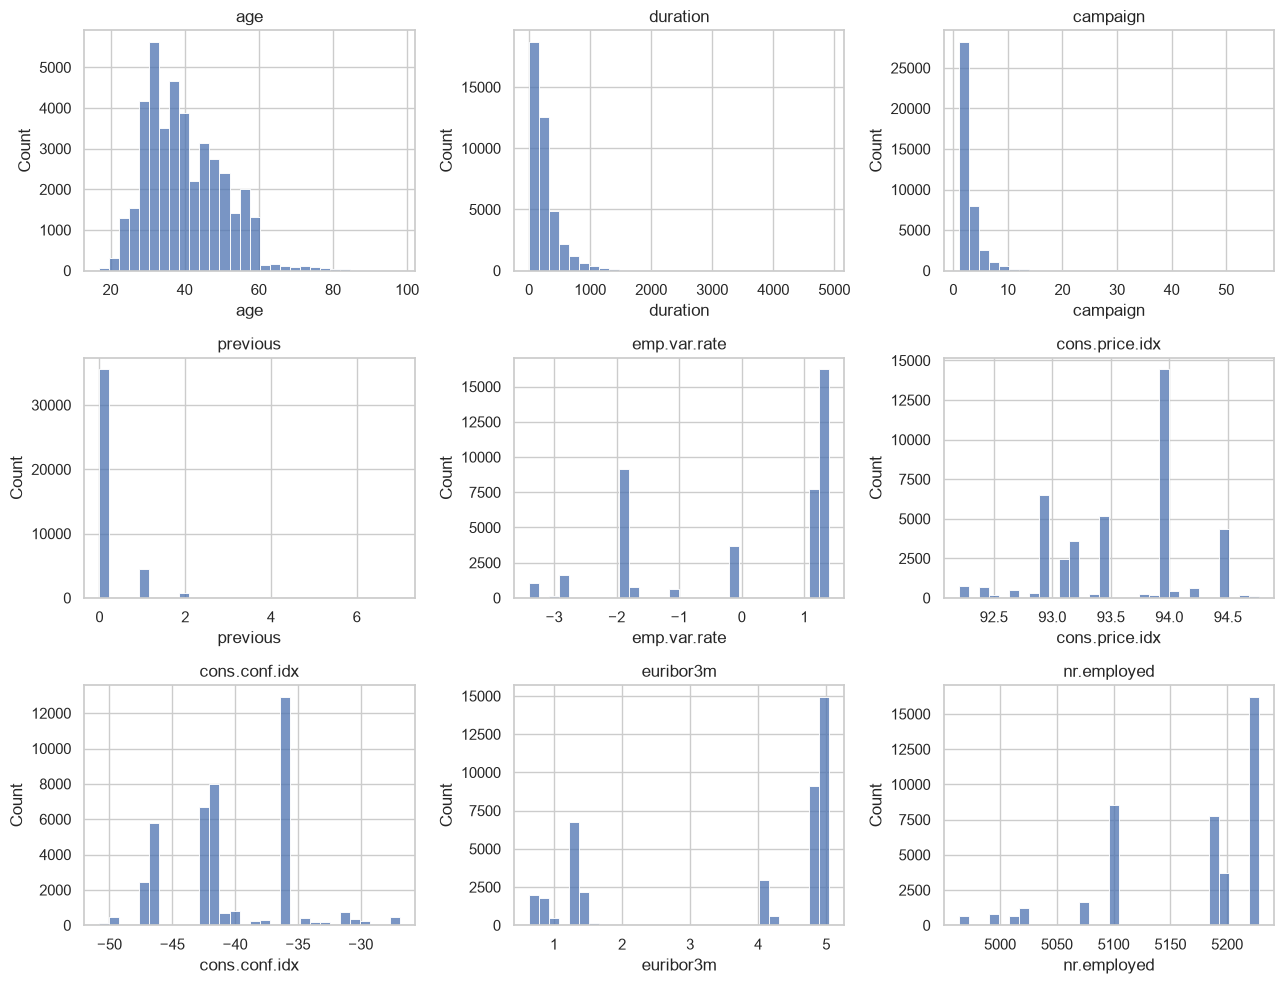

In [9]:
show_cols = ["age", "duration", "campaign", "previous", "emp.var.rate",
             "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.ravel(), show_cols):
    sns.histplot(raw[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col)
save("numeric_histograms")

### 2.4 Outliers – box plots
Box plots show outliers. We compare the two classes to see which columns separate them.

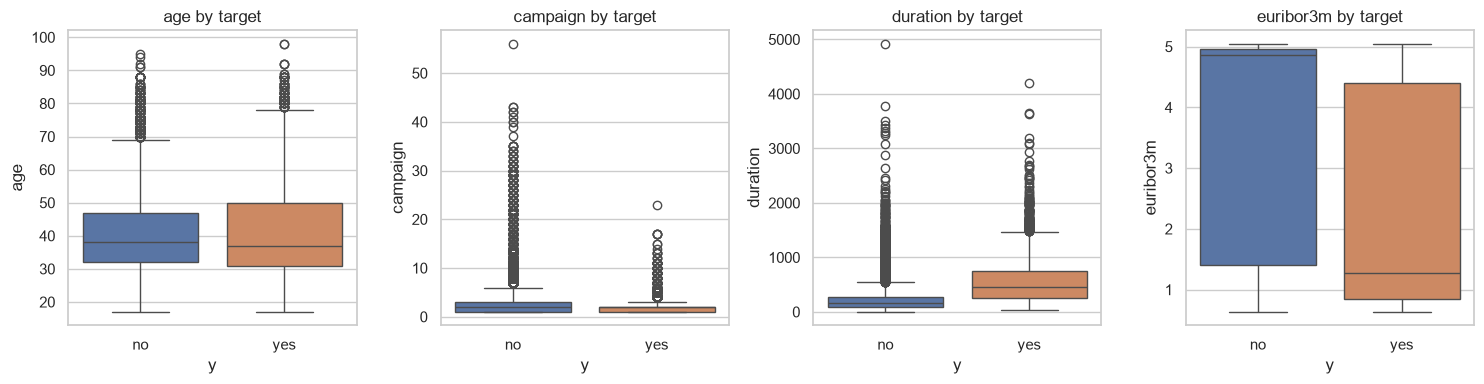

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["age", "campaign", "duration", "euribor3m"]):
    sns.boxplot(data=raw, x="y", y=col, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_title(f"{col} by target")
save("boxplots_by_target")

In [11]:
# How many outliers does the IQR rule find?
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(raw[c]) for c in ["age", "campaign", "duration", "previous"]}, name="IQR outliers")

age          469
campaign    2406
duration    2963
previous    5625
Name: IQR outliers, dtype: int64

### 2.5 Correlation matrix
Correlation shows linear links between numeric columns. Very high correlation (> 0.9) means two columns
carry almost the same information. This is a problem for Logistic Regression (multicollinearity).

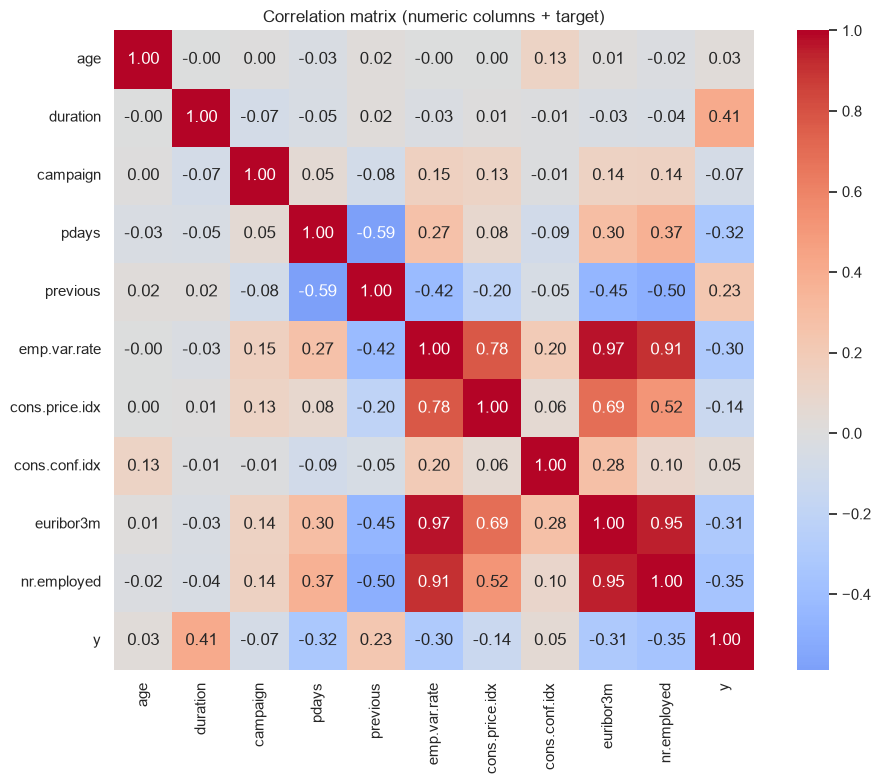

nr.employed      -0.354678
pdays            -0.324914
euribor3m        -0.307771
emp.var.rate     -0.298334
cons.price.idx   -0.136211
campaign         -0.066357
age               0.030399
cons.conf.idx     0.054878
previous          0.230181
duration          0.405274
Name: y, dtype: float64

In [12]:
corr_df = raw[num_cols].copy()
corr_df["y"] = (raw["y"] == "yes").astype(int)
corr = corr_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (numeric columns + target)")
save("correlation_matrix")
corr["y"].drop("y").sort_values()

### 2.6 Subscription rate by category
For each category we show the percentage of "yes". This tells us which client groups and which call conditions are better.
The dashed line is the average rate (11.3%).

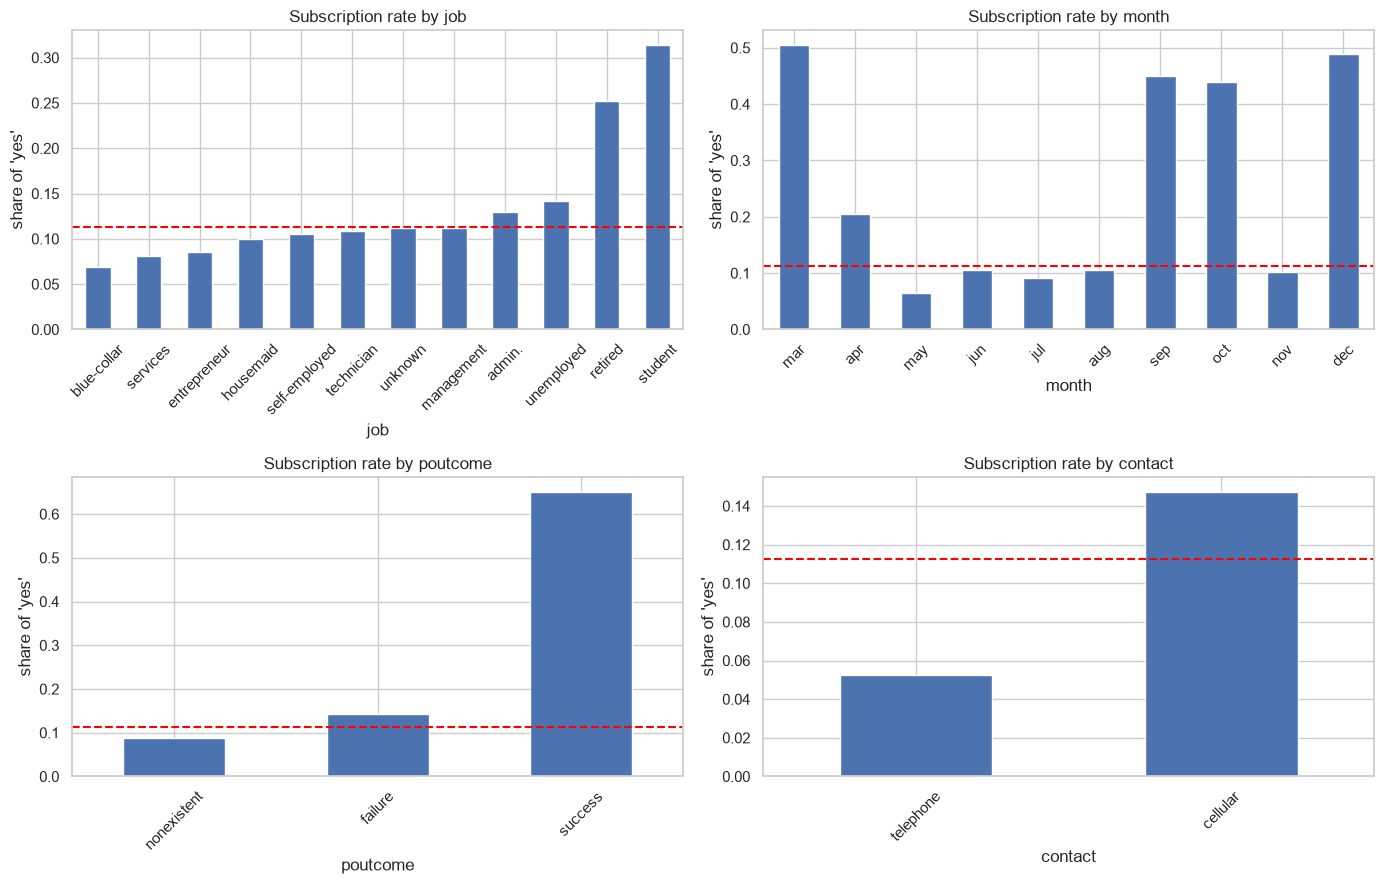

In [13]:
rate = (raw["y"] == "yes").mean()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
for ax, col in zip(axes.ravel(), ["job", "month", "poutcome", "contact"]):
    r = raw.groupby(col)["y"].apply(lambda s: (s == "yes").mean())
    r = r.reindex(month_order) if col == "month" else r.sort_values()
    r.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.axhline(rate, ls="--", color="red")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_ylabel("share of 'yes'")
    ax.tick_params(axis="x", rotation=45)
save("rate_by_category")

In [14]:
# Number of calls per month: most calls were in May, but May has the lowest success rate
raw["month"].value_counts().reindex(month_order)

month
mar      546
apr     2632
may    13769
jun     5318
jul     7174
aug     6178
sep      570
oct      718
nov     4101
dec      182
Name: count, dtype: int64

### 2.7 Scatter plot of economic indicators
We check how the economy (interest rate and consumer confidence) is linked to the result.

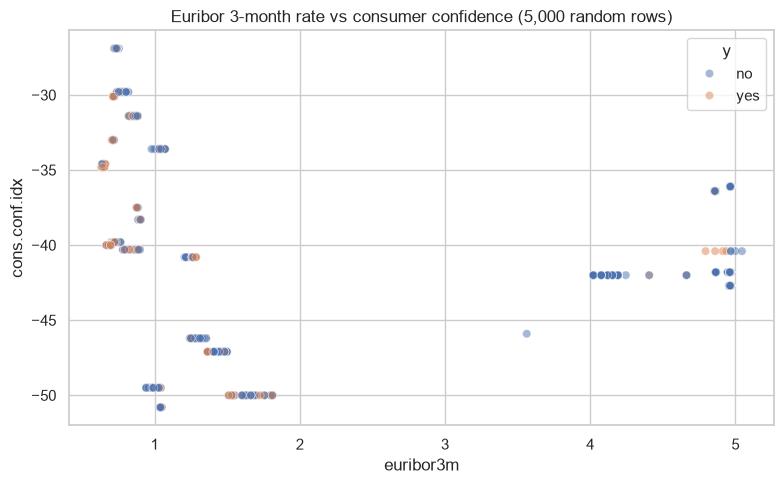

In [15]:
sample = raw.sample(5000, random_state=RANDOM_STATE)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="euribor3m", y="cons.conf.idx", hue="y", alpha=0.5,
                palette={"no": "#4C72B0", "yes": "#DD8452"})
plt.title("Euribor 3-month rate vs consumer confidence (5,000 random rows)")
save("scatter_euribor_conf")

In [16]:
# Success rate by euribor level: low interest rate -> many more 'yes'
pd.crosstab(pd.cut(raw["euribor3m"], [0, 1, 2, 4, 6]), raw["y"], normalize="index").round(3)

y,no,yes
euribor3m,,
"(0, 1]",0.543,0.457
"(1, 2]",0.842,0.158
"(2, 4]",0.929,0.071
"(4, 6]",0.952,0.048


### 2.8 Checking data errors
`pdays = 999` should mean "not contacted before". Then `previous` should be 0 and `poutcome` should be "nonexistent".
We check if this is always true.

In [17]:
pd.crosstab(raw["pdays"] == 999, raw["poutcome"], rownames=["pdays == 999"])

poutcome,failure,nonexistent,success
pdays == 999,,,
False,142,0,1373
True,4110,35563,0


4,110 rows have `pdays = 999` but `poutcome = failure` (and `previous > 0`). So these clients **were** contacted before,
but `pdays` says they were not. This is an error in the data. We will fix it in data preparation.

## 3. Data preparation

All steps are in `src/bank_ml.py`, so the Streamlit app uses exactly the same code.

| Step | What we do | Why |
|---|---|---|
| Duplicates | remove 12 duplicated rows | the same call should not be counted twice |
| Leakage | drop `duration` | it is only known after the call (UCI note) |
| Correlation | drop `emp.var.rate`, `nr.employed` | correlation > 0.9 with `euribor3m` |
| Missing values | `unknown` → NaN, then fill with the most frequent value (fitted on train only) | the models need complete data |
| `default` | keep `unknown` as its own category | 21% unknown; "unknown" itself carries information |
| Data errors | do not trust `pdays = 999`; use `previous > 0` for "contacted before" | 4,110 rows had a wrong code |
| Rare category | join `illiterate` (18 rows) with `basic.4y` | too small to learn from |
| Outliers | cap `campaign`, `previous`, `total_contacts` at the 99th percentile | very long tails, but the values are real |
| New features | `was_contacted_before`, `days_since_last`, `total_contacts`, `age_group` | give clearer signals to the models |
| Encoding | one-hot encoding for categorical columns | models need numbers |
| Scaling | StandardScaler for numeric columns | KNN and Logistic Regression are sensitive to scale |

In [18]:
step1 = clean(raw)
print("After cleaning:", step1.shape)
print("Missing values after 'unknown' -> NaN:")
print(step1.isna().sum()[lambda s: s > 0])

After cleaning: (41176, 18)
Missing values after 'unknown' -> NaN:
job           330
marital        80
education    1730
housing       990
loan          990
dtype: int64


In [19]:
df = add_features(step1)
print("After feature engineering:", df.shape)
df[["previous", "was_contacted_before", "days_since_last", "campaign", "total_contacts", "age", "age_group"]].head(8)

After feature engineering: (41176, 21)


,previous,was_contacted_before,days_since_last,campaign,total_contacts,age,age_group
0,0,0,NaN,1,1,56,51-65
1,0,0,NaN,1,1,57,51-65
2,0,0,NaN,1,1,37,36-50
3,0,0,NaN,1,1,40,36-50
4,0,0,NaN,1,1,56,51-65
5,0,0,NaN,1,1,45,36-50
6,0,0,NaN,1,1,59,51-65
7,0,0,NaN,1,1,41,36-50


In [20]:
# The new feature shows a clear difference in the target
df.groupby("was_contacted_before")["y"].agg(["mean", "count"]).rename(columns={"mean": "subscription_rate"})

,subscription_rate,count
was_contacted_before,,
0,0.088324,35551
1,0.266489,5625


### 3.1 Train / validation / test split
We use a **stratified** split, so every set has the same share of "yes" (about 11%).
- **Train (70%)** – to fit the models and do 5-fold cross-validation for tuning.
- **Validation (15%)** – to choose the decision threshold for each model.
- **Test (15%)** – used only once at the end, to compare the final models fairly.

In [21]:
X, y = split_xy(df)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=RANDOM_STATE)

split_info = pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    "share_yes": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"]).round(4)
split_info

,rows,share_yes
train,28822,0.1127
validation,6177,0.1127
test,6177,0.1127


In [22]:
# The preprocessor is fitted on the training data only (no leakage).
pre = build_preprocessor()
X_train_t = pre.fit_transform(X_train)
print("Features after encoding:", X_train_t.shape[1])
print("Mean of scaled numeric columns (should be ~0):", X_train_t[:, :9].mean(axis=0).round(2))
print("Std of scaled numeric columns (should be ~1):", X_train_t[:, :9].std(axis=0).round(2))

Features after encoding: 61
Mean of scaled numeric columns (should be ~0): [ 0.  0. -0.  0.  0.  0. -0. -0.  0.]
Std of scaled numeric columns (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 4. Model training

This is a **supervised binary classification** problem. We train four different kinds of model:

| Model | Type | Why we chose it |
|---|---|---|
| Logistic Regression | linear | simple, fast, easy to explain (coefficients); a strong baseline |
| K-Nearest Neighbours | distance-based | no assumptions about the shape of the data |
| Decision Tree | rule-based | easy to read rules; handles non-linear patterns |
| Random Forest | ensemble of trees | usually more accurate and more stable than one tree |

**Tuning:** `GridSearchCV` with 5-fold **stratified** cross-validation on the training set.
**Tuning score:** average precision (PR-AUC). It focuses on the "yes" class, so it is better than accuracy for imbalanced data.
**Imbalance:** `class_weight="balanced"` is one of the options in the grid, so the search decides if it helps.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.1, 1, 10],
         "model__class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [25, 75, 151, 251, 351],
         "model__weights": ["uniform", "distance"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [4, 6, 8, 10, 12, 15],
         "model__min_samples_leaf": [20, 50, 100],
         "model__class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [8, 12, None],
         "model__min_samples_leaf": [5, 20],
         "model__max_features": ["sqrt", 0.3],
         "model__class_weight": [None, "balanced_subsample"]}),
}

In [24]:
best_models, cv_results = {}, []
for name, (estimator, grid) in models.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("model", estimator)])
    search = GridSearchCV(pipe, grid, scoring="average_precision", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    cv_results.append({"model": name, "best CV PR-AUC": round(search.best_score_, 4),
                       "combinations tried": len(search.cv_results_["params"]),
                       "best parameters": params})
    print(f"{name}: PR-AUC={search.best_score_:.4f}  {params}")

cv_table = pd.DataFrame(cv_results).set_index("model")
cv_table

Logistic Regression: PR-AUC=0.4443  {'C': 0.1, 'class_weight': None}


KNN: PR-AUC=0.4272  {'n_neighbors': 151, 'weights': 'uniform'}


Decision Tree: PR-AUC=0.4363  {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 100}


Random Forest: PR-AUC=0.4668  {'class_weight': 'balanced_subsample', 'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 20}


,best CV PR-AUC,combinations tried,best parameters
model,,,
Logistic Regression,0.4443,8,"{'C': 0.1, 'class_weight': None}"
KNN,0.4272,10,"{'n_neighbors': 151, 'weights': 'uniform'}"
Decision Tree,0.4363,36,"{'class_weight': 'balanced', 'max_depth': 10, ..."
Random Forest,0.4668,24,"{'class_weight': 'balanced_subsample', 'max_de..."


In [25]:
# Example: how C and class_weight change the cross-validation score of Logistic Regression
lr_search = GridSearchCV(Pipeline([("prep", build_preprocessor()), ("model", LogisticRegression(max_iter=2000))]),
                         models["Logistic Regression"][1], scoring="average_precision", cv=cv, n_jobs=-1)
lr_search.fit(X_train, y_train)
pd.DataFrame(lr_search.cv_results_)[["param_model__C", "param_model__class_weight", "mean_test_score", "std_test_score"]].round(4)

,param_model__C,param_model__class_weight,mean_test_score,std_test_score
0,0.01,NaN,0.4397,0.0255
1,0.01,balanced,0.4359,0.0241
2,0.10,NaN,0.4443,0.0258
3,0.10,balanced,0.4390,0.0246
4,1.00,NaN,0.4441,0.0253
5,1.00,balanced,0.4386,0.0244
6,10.00,NaN,0.4441,0.0253
7,10.00,balanced,0.4383,0.0243


### 4.1 Choosing the decision threshold on the validation set
By default a model says "yes" when the probability is above 0.5. With imbalanced data, 0.5 is often not the best choice.
For each model we choose the threshold that gives the best **F1-score** on the **validation** set.
The test set is not used here, so the final test results stay fair.

In [26]:
thresholds = {}
for name, model in best_models.items():
    p_val = model.predict_proba(X_val)[:, 1]
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = np.argmax(f1[:-1])
    thresholds[name] = float(thr[best])
    print(f"{name}: threshold={thr[best]:.3f}  validation F1={f1[best]:.3f}")

Logistic Regression: threshold=0.236  validation F1=0.483


KNN: threshold=0.219  validation F1=0.488
Decision Tree: threshold=0.669  validation F1=0.495
Random Forest: threshold=0.626  validation F1=0.507


## 5. Model evaluation on the test set

We use these metrics:
- **TPR / Recall** – the share of real subscribers that the model finds. Missing a subscriber means lost income.
- **TNR / Specificity** – the share of "no" clients that the model correctly skips. Each wrong call costs time.
- **Precision** – when the model says "yes", how often it is right. This shows how efficient the calls are.
- **F1-score** – balance between precision and recall.
- **ROC-AUC** – ranking quality over all thresholds.
- **PR-AUC** – like ROC-AUC, but it focuses on the rare "yes" class. It is our main metric.
- **Accuracy** – shown only for comparison; it is misleading here.

A **Dummy** model (always predicts the majority class) is our baseline.

In [27]:
def evaluate(name, model, threshold):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"model": name, "threshold": round(threshold, 3),
            "TPR (Recall)": tp / (tp + fn), "TNR": tn / (tn + fp),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba),
            "PR-AUC": average_precision_score(y_test, proba),
            "Accuracy": accuracy_score(y_test, pred)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
rows = [evaluate("Dummy (always 'no')", dummy, 0.5)]
rows += [evaluate(n, m, thresholds[n]) for n, m in best_models.items()]
results = pd.DataFrame(rows).set_index("model").round(4)
results

,threshold,TPR (Recall),TNR,Precision,F1,ROC-AUC,PR-AUC,Accuracy
model,,,,,,,,
Dummy (always 'no'),0.500,0.0000,1.0000,0.0000,0.0000,0.5000,0.1127,0.8873
Logistic Regression,0.236,0.5201,0.9288,0.4814,0.5000,0.7957,0.4564,0.8828
KNN,0.219,0.5445,0.9194,0.4616,0.4997,0.7958,0.4438,0.8771
Decision Tree,0.669,0.5963,0.9071,0.4491,0.5123,0.7975,0.4609,0.8721
Random Forest,0.626,0.5948,0.9168,0.4759,0.5287,0.8174,0.4954,0.8805


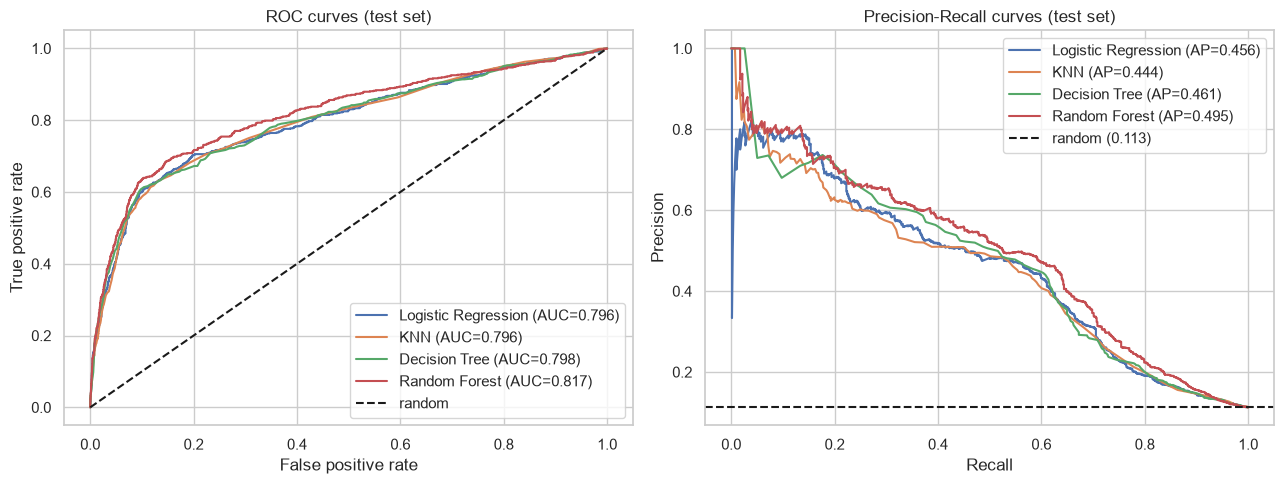

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, model in best_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="random")
axes[0].set(title="ROC curves (test set)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"random ({y_test.mean():.3f})")
axes[1].set(title="Precision-Recall curves (test set)", xlabel="Recall", ylabel="Precision")
axes[0].legend(); axes[1].legend()
save("roc_pr_curves")

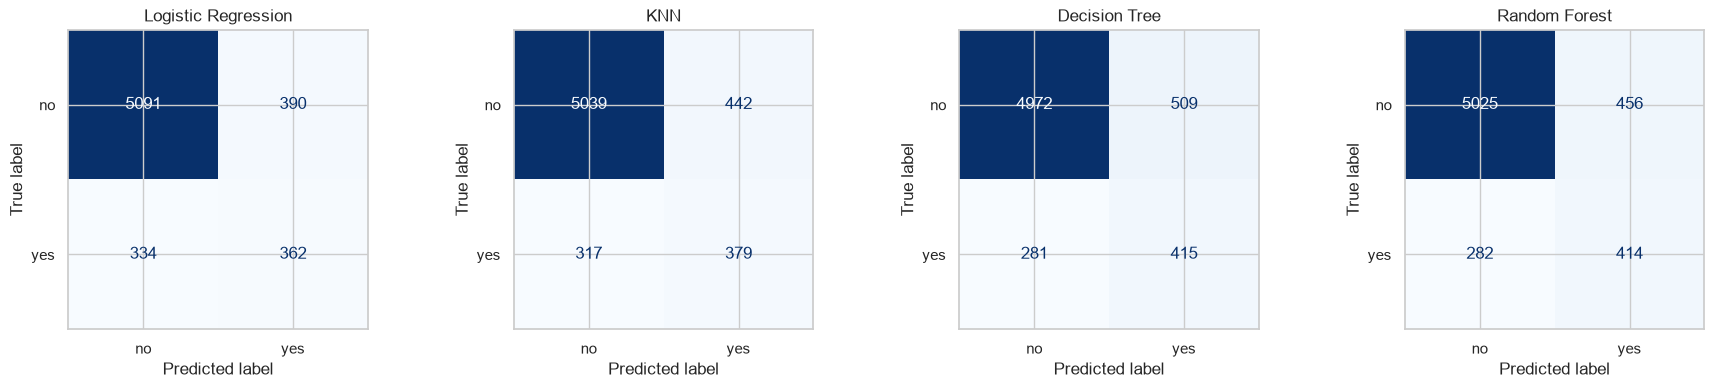

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    pred = (model.predict_proba(X_test)[:, 1] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["no", "yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
save("confusion_matrices")

### 5.1 Business view: cumulative gains
The bank can sort clients by the predicted probability and call the top ones first.
The gains curve shows what share of all subscribers we reach if we call the top X% of clients.

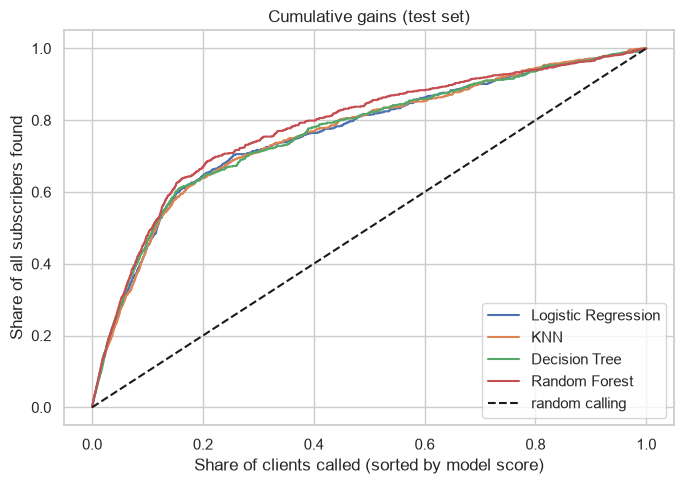

,top 10%,top 20%,top 30%,top 50%
Logistic Regression,0.448,0.645,0.717,0.815
KNN,0.450,0.639,0.711,0.820
Decision Tree,0.464,0.641,0.711,0.820
Random Forest,0.478,0.668,0.743,0.849


In [30]:
plt.figure(figsize=(7, 5))
gains_table = {}
for name, model in best_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    order = np.argsort(-proba)
    cum = np.cumsum(y_test.values[order]) / y_test.sum()
    share = np.arange(1, len(cum) + 1) / len(cum)
    plt.plot(share, cum, label=name)
    gains_table[name] = {f"top {p}%": round(cum[int(len(cum) * p / 100) - 1], 3) for p in [10, 20, 30, 50]}
plt.plot([0, 1], [0, 1], "k--", label="random calling")
plt.xlabel("Share of clients called (sorted by model score)")
plt.ylabel("Share of all subscribers found")
plt.title("Cumulative gains (test set)")
plt.legend()
save("cumulative_gains")
pd.DataFrame(gains_table).T

### 5.2 Which features matter?
We use **permutation importance** on the test set for the best model. It measures how much PR-AUC falls when one
original column is shuffled. This works for any model and is easy to explain.

Best model by test PR-AUC: Random Forest


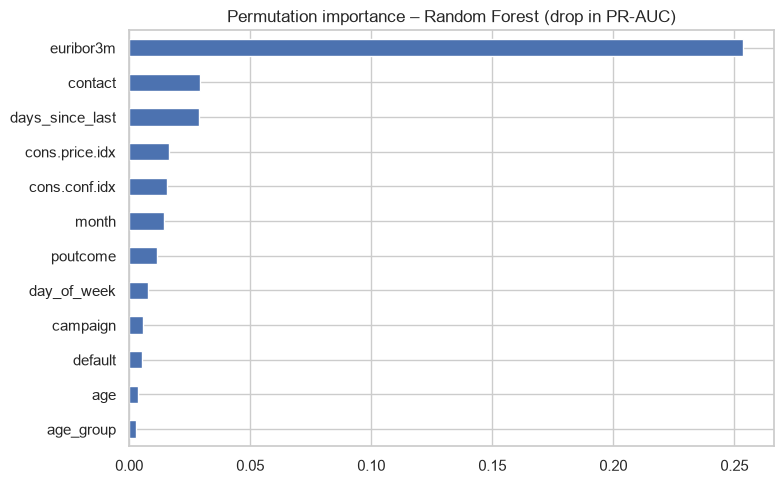

euribor3m          0.2537
contact            0.0293
days_since_last    0.0287
cons.price.idx     0.0165
cons.conf.idx      0.0158
month              0.0143
poutcome           0.0117
day_of_week        0.0079
campaign           0.0057
default            0.0053
dtype: float64

In [31]:
best_name = results.drop(index="Dummy (always 'no')")["PR-AUC"].idxmax()
print("Best model by test PR-AUC:", best_name)
perm = permutation_importance(best_models[best_name], X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.tail(12).plot(kind="barh", figsize=(8, 5), color="#4C72B0")
plt.title(f"Permutation importance – {best_name} (drop in PR-AUC)")
save("feature_importance")
importance.sort_values(ascending=False).round(4).head(10)

In [32]:
# Logistic Regression coefficients: positive = more likely 'yes'
lr = best_models["Logistic Regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
pd.concat([coefs.head(6), coefs.tail(6)]).round(3)

num__euribor3m              -0.901
cat__poutcome_failure       -0.791
cat__month_may              -0.774
cat__contact_telephone      -0.478
cat__poutcome_nonexistent   -0.355
cat__default_unknown        -0.338
cat__job_student             0.192
num__cons.conf.idx           0.200
cat__month_dec               0.230
num__cons.price.idx          0.264
cat__poutcome_success        0.719
cat__month_mar               0.878
dtype: float64

## 6. Save the models for the Streamlit app

In [33]:
for name, model in best_models.items():
    joblib.dump(model, MODELS / f"{name.lower().replace(' ', '_')}.joblib")

meta = {
    "best_model": best_name,
    "thresholds": thresholds,
    "test_results": results.reset_index().to_dict(orient="records"),
    "cv_results": [{**r, "best parameters": {k: str(v) for k, v in r["best parameters"].items()}} for r in cv_results],
    "gains": gains_table,
    "importance": importance.sort_values(ascending=False).round(5).to_dict(),
    "split": split_info.reset_index().rename(columns={"index": "set"}).to_dict(orient="records"),
}
with open(MODELS / "metrics.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'metrics.json', 'random_forest.joblib']


## 7. Short summary

- The data is imbalanced (11.3% "yes"), so we used PR-AUC, recall, precision and F1 instead of accuracy.
- `duration` was removed because it leaks the answer. Without it, the task is realistic but harder.
- The economic context (`euribor3m`, `cons.conf.idx`), the result of the previous campaign and the month are the strongest signals.
- The final model choice and its business meaning are discussed in the report.